# Final capstone | historical optimisation and reproducible evidence

**Imperial College London · Machine Learning & AI · Black-Box Optimisation**

This is the project's **executable research guide**, not a claim that the original candidate-selection code from every round has survived.

**Part A — What I implemented:** audit all **104** personal portal queries against original decision ledgers; trace surviving historical scripts; run real GP, acquisition, HEBO-inspired and TuRBO-style **method demonstrations** at an honest data cutoff. Demonstration proposals are *not* historic portal returns or proof of the exact old selection algorithm.

**Part B — What happened:** verify all **279** observed results (175 supplied + 104 personal), final bests, progress and retained pre-result forecast errors.

**Part C — What the evidence explains:** independently check retrospective F1 and F8 parameter fits, the F7 positive Hartmann-6 equation, and the F5 boundary score. No unobserved scores are represented as oracle results.

**Verified historical fact:** the **Round 11 F7 input is confirmed**, `0.233000-0.128000-0.522000-0.276000-0.310000-0.667000`, returning `3.278967926227992`. The original *candidate-selection script* is unavailable, **not** the input. See the [verified evidence register](../docs/VERIFIED_FACTS.md).

**Inputs:** [observations](../data/all_observations.csv), [final bests](../results/current_best_after_week13.csv), [historical records](../journey/README.md), and the source files in [src/bbo](../src/bbo/README.md).

In [1]:
# Make the notebook work when Jupyter starts in the repository root OR notebooks/.
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

cwd = Path.cwd().resolve()
ROOT = next((p for p in [cwd, *cwd.parents] if (p / 'data/all_observations.csv').exists()), None)
if ROOT is None:
    raise FileNotFoundError("Clone the repository and open the notebook from inside it.")
sys.path.insert(0, str(ROOT / 'src'))

from bbo.structural_validation import recover_f8, f5_at
from bbo.surrogates import fit_gp, inverse_mean
from bbo.acquisition import expected_improvement
from bbo.search import sobol_points, portal_string
from bbo.evidence_audit import audit_portal_history
from bbo.f1_reconstruction import load_own_observations, fit_initial_only, validate_held_out, predict as predict_f1
from bbo.f7_reconstruction import f7_hypothesis, validate_recorded_f7
from bbo.optimizer import hebo_inspired_committee, turbo_style_candidate

print("Repository folder:", ROOT.name)

Repository folder: bbo-capstone-imperial-college


## Part A · What I implemented and what survived

The original problem was to choose **one input per function per round**. The portal returned the actual score. Models, acquisition functions and human judgement were used to propose candidates, but later code cannot establish that it generated a particular historical point unless a matching contemporary script or decision record survives.

| Stage | Surviving original work | Evidence status |
|---|---|---|
| Early UCB/GP work | [Round 2 Python script](../journey/round_02/week2_ucb_course_aligned.py) and [original notebook](../journey/round_02/Capstone_BBO_Week2_UCB_only.ipynb) | Surviving working package. Some original course `.npy` inputs are not in this public clone. |
| Alternative surrogate models | [Round 4 Python code](../journey/round_04/capstone_bbo_week4_module15.py) and [notebook](../journey/round_04/Capstone_BBO_Week4_Module15.ipynb) | Historical GP, SVM and small neural-network diagnostics; not an exact generator for every submitted query. |
| Local model and forecast investigation | [Round 9 controlled fits](../journey/round_09/round9_controlled_fits.py) and [forecast audit](../results/week9_forecast_audit.csv) | Preserved scripts and pre-result forecasts. |
| Candidate challenges and structural tests | [Round 10 decision audit](../journey/round_10/README.md) and [historical related challenger code](../src/bbo/optimizer.py) | Some code is related; exact provenance of every submitted candidate is not fully reproducible from the preserved sources. |
| Final decisions | [Rounds 11–13](../journey/README.md) with official portal returns | Original selections and scores are known. Some exact candidate-generating scripts are not. |

**Audit principle:** replaying an algorithm later is *not* evidence that this same implementation chose the historic candidate. The code below makes that distinction testable.


In [2]:
# Check all 104 actual submissions against the eight separate decision ledgers.
# The audit also checks the confirmed F7 R11 record in two source CSVs.
facts = audit_portal_history(ROOT)
display(pd.DataFrame([facts]).T.rename(columns={0: 'Verified value'}))

all_ledgers = []
for function_id in range(1, 9):
    ledger = pd.read_csv(ROOT / f'functions/F{function_id}/selection_history.csv')
    ledger.insert(0, 'Function', function_id)
    all_ledgers.append(ledger)
decisions = pd.concat(all_ledgers, ignore_index=True)
assert len(decisions) == 104
assert len(decisions.loc[decisions['Function'].eq(7) & decisions['round'].eq(11)]) == 1
display(decisions.loc[
    decisions['Function'].isin([1, 4, 7, 8]) & decisions['round'].isin([2, 9, 10, 11, 12]),
    ['Function', 'round', 'submitted_input', 'actual_output', 'selection_rationale', 'code_evidence_status']
].sort_values(['round', 'Function']).reset_index(drop=True))
print('Verified: every recorded input and score agrees with its function ledger.')


,Verified value
total_observations,279
initial_observations,175
portal_returns,104
confirmed_f7_r11,0.233000-0.128000-0.522000-0.276000-0.310000-0...
f7_r11_score,3.278967926227992


,Function,round,submitted_input,actual_output,selection_rationale,code_evidence_status
0,1,2,0.052001-0.865999,-1.963245e-233,GP and UCB working package,related_historical_script_not_verified_exact
1,4,2,0.415636-0.429159-0.368928-0.413098,6.475543e-01,GP and UCB working package,related_historical_script_not_verified_exact
2,7,2,0.074002-0.315323-0.247287-0.026732-0.35885-0....,1.020402e+00,GP and UCB working package,related_historical_script_not_verified_exact
3,8,2,0.321822-0.045429-0.355724-0.015612-0.965914-0...,9.497749e+00,GP and UCB working package,related_historical_script_not_verified_exact
4,1,9,0.729874-0.7318,1.921281e-15,One-coordinate probe: move x1 down by 0.001 fr...,related_historical_analysis_not_verified_exact
5,4,9,0.42038-0.427768-0.368794-0.412497,6.589329e-01,Continue the controlled x1 micro-step. The las...,related_historical_analysis_not_verified_exact
6,7,9,0.228702-0.36927-0.256273-0.262985-0.391467-0....,1.786338e+00,The updated quadratic across the controlled x1...,related_historical_analysis_not_verified_exact
7,8,9,0.128076-0.104109-0.074587-0.102502-0.970754-0...,9.932443e+00,Continue the newly validated x6 direction with...,related_historical_analysis_not_verified_exact
8,1,10,0.582552-0.558941,7.264001e-06,Targeted positive-response region; exploratory...,related_challenger_not_verified_exact
9,4,10,0.420370-0.427768-0.368794-0.412497,6.589624e-01,Controlled local refinement supported by prosp...,related_challenger_not_verified_exact


Verified: every recorded input and score agrees with its function ledger.


### Run the optimisation mechanisms without rewriting history

The following examples use **F2 data available up to Round 9 only**, so they do not learn from later returns.

- **GP + Expected Improvement:** demonstrated in Part B below with a Matérn 2.5 model and a Sobol candidate pool.
- **HEBO-inspired committee:** combines three surrogate kernels and ranked EI/PI/UCB suggestions. This is a *custom educational adaptation*, not the official HEBO library.
- **TuRBO-style local search:** searches an incumbent-centred trust region using EI. It is *not* the complete adaptive TuRBO implementation.

These run the repository's actual reusable Python functions. Their output is a **new counterfactual proposal**, not a submitted point or observed score. The full official HEBO/TuRBO-1 packages belong to [post-capstone simulator research](../research/full_optimisers/README.md).

In [3]:
# A real, executable challenger comparison at a historical information cutoff.
# It is NOT a replay of the original R10 proposal or its portal result.
f2_cutoff = observations if 'observations' in globals() else pd.read_csv(ROOT / 'data/all_observations.csv')
f2_cutoff = f2_cutoff.loc[
    (f2_cutoff['function'] == 2) & (f2_cutoff['round'] <= 9)
]
X2 = f2_cutoff[['x1', 'x2']].to_numpy(float)
y2 = f2_cutoff['output'].to_numpy(float)

committee = hebo_inspired_committee(X2, y2, seed=109, n_power=9)
trust = turbo_style_candidate(X2, y2, length=0.20, seed=909, n_power=9)
display(committee[['kernel', 'candidate', 'predicted_mean', 'transformed_sd', 'robust_rank']])
print('TuRBO-style unsubmitted candidate:', trust['candidate'])
print('TuRBO-style predicted score:', round(trust['predicted_mean'], 6))
print('Actual recorded F2 R10 query: 0.701500-0.959796 (not generated by this rerun)')
print('No oracle return exists for these unsubmitted candidates in this demonstration.')


,kernel,candidate,predicted_mean,transformed_sd,robust_rank
0,RBF,0.862978-0.982302,0.613683,0.656403,0.997065
1,Matern15,0.896610-0.998888,0.574941,0.751930,0.998043
2,Matern25,0.896610-0.998888,0.583811,0.750641,0.998043


TuRBO-style unsubmitted candidate: 0.799967-0.983168
TuRBO-style predicted score: 0.619928
Actual recorded F2 R10 query: 0.701500-0.959796 (not generated by this rerun)
No oracle return exists for these unsubmitted candidates in this demonstration.


## Part B · What was actually observed

All charts and recorded bests in this part use **real returned observations only**. Historical Round 11 F7 has six confirmed coordinates; the missing item is its old query-selection script.

### B1. Dataset completeness and verified portal evidence

I start with the exact historical observations, not model-generated guesses. The programme supplied 175 starting points, followed by my 104 returned portal queries. The Round 11 F7 input was confirmed from the official weekly results email, so all 279 records now have complete inputs in their declared dimensions. Its original selection script has not been reconstructed.

In [4]:
observations = pd.read_csv(ROOT / 'data/all_observations.csv')
required = {'function', 'round', 'source', 'input_status', 'output'}
assert required.issubset(observations.columns)
assert len(observations) == 279
assert (observations['source'] == 'course_initial').sum() == 175
assert (observations['source'] == 'personal_portal').sum() == 104
assert observations['output'].notna().all()

missing = observations.loc[observations['input_status'] == 'missing_input']
assert len(missing) == 0
r11 = observations.loc[(observations['function'] == 7) & (observations['round'] == 11)].iloc[0]
assert r11['input_status'] == 'confirmed' and abs(float(r11['x1']) - 0.233) < 1e-15

display(pd.DataFrame({
    'Dataset': ['Course initial', 'Personal portal', 'Total', 'Rows missing required input'],
    'Records': [175, 104, len(observations), len(missing)]
}))
display(observations.groupby('function', as_index=False)['output'].agg(['count','max']))

,Dataset,Records
0,Course initial,175
1,Personal portal,104
2,Total,279
3,Rows missing required input,0


,function,count,max
0,1,23,2.000000
1,2,23,0.744250
2,3,28,-0.003753
3,4,43,0.746898
4,5,33,8662.405001
5,6,33,-0.037519
6,7,43,3.322368
7,8,53,10.000000


### B2. Verify the final bests

A final result must be the **largest observed return** for that function, not the latest return or a GP prediction. I recompute all eight maxima from the complete record and compare them with the published results table.

In [5]:
published = pd.read_csv(ROOT / 'results/current_best_after_week13.csv')
computed = observations.groupby('function')['output'].max().sort_index()
stored = published.set_index('Function')['Final_Best'].sort_index()
np.testing.assert_allclose(computed.to_numpy(), stored.to_numpy(), atol=1e-12, rtol=1e-12)

view = published[['Function', 'Final_Best', 'First_Achieved_Round', 'Best_Input']]
display(view)
print("All eight final bests reproduce exactly within floating-point tolerance.")

,Function,Final_Best,First_Achieved_Round,Best_Input
0,1,2.000000,11,0.628540-0.628540
1,2,0.744250,13,0.864900-0.500000
2,3,-0.003753,13,0.197280-0.523429-0.470094
3,4,0.746898,13,0.416903-0.415704-0.360320-0.415205
4,5,8662.405001,10,0.999999-0.999999-0.999999-0.999999
5,6,-0.037519,12,0.415080-0.344119-0.644062-0.776818-0.076258
6,7,3.322368,12,0.201689-0.150011-0.476874-0.275332-0.311652-0...
7,8,10.000000,10,0.100000-0.150000-0.130000-0.150000-0.800000-0...


All eight final bests reproduce exactly within floating-point tolerance.


### B3. Progress through thirteen rounds

For every function I take the best output of each round and calculate its cumulative maximum. Each subplot has its **own y-axis scale**: scores across different functions cannot be added or compared directly.

The first round in this notebook is `round=0`, representing the programme's starting data. The remaining 13 rounds are my returned queries.

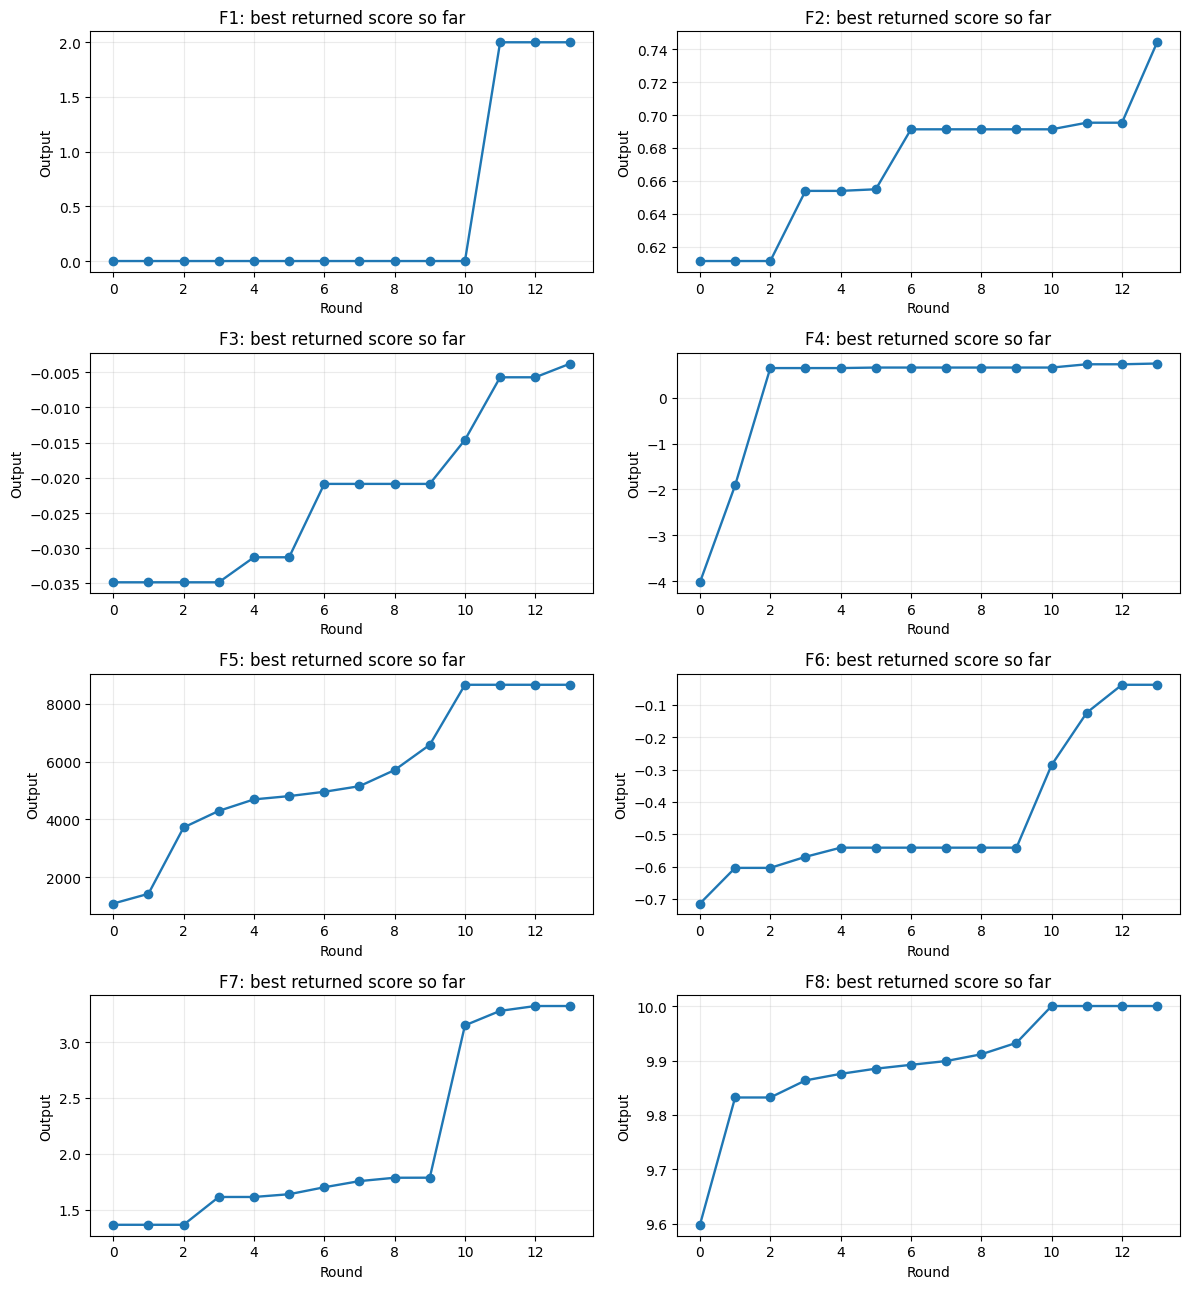

In [6]:
fig, axes = plt.subplots(4, 2, figsize=(12, 13))
for function_id, axis in zip(range(1, 9), axes.flat):
    records = observations.loc[observations['function'] == function_id]
    best_by_round = records.groupby('round')['output'].max().sort_index().cummax()
    axis.plot(best_by_round.index, best_by_round.to_numpy(), marker='o', linewidth=1.7)
    axis.set(title=f'F{function_id}: best returned score so far', xlabel='Round', ylabel='Output')
    axis.grid(alpha=0.25)
plt.tight_layout()
plt.show()

### B4. Illustrative Gaussian Process decision

This is a **separate retrospective example**, not a reconstruction of the exact candidate chosen in the course. I use F2's observations available **through Round 9**. A Matérn 2.5 GP, fitted with a Yeo–Johnson response transformation, predicts scores and uncertainty across a Sobol candidate pool. Expected Improvement (EI) balances predicted gains and uncertainty.

The algorithm proposes an input only. Without querying the real portal at that exact input, **its true score is unknown**.

In [7]:
history_f2 = observations.loc[(observations['function'] == 2) & (observations['round'] <= 9)]
X = history_f2[['x1', 'x2']].to_numpy(float)
y = history_f2['output'].to_numpy(float)

# No later observations are available to this illustrative Week 9 decision.
model, transform, transformed_y = fit_gp(
    X, y, kernel='Matern25', transform='yeo-johnson', seed=25, restarts=0
)
pool = sobol_points(d=2, n_power=9, seed=25)
mu, sd = model.predict(pool, return_std=True)
ei = expected_improvement(mu, sd, float(transformed_y.max()))
winner = int(np.argmax(ei))
proposal = pool[winner]
predicted_raw_scale = float(inverse_mean([mu[winner]], transform)[0])

print('Best returned F2 score available through R9:', round(float(y.max()), 6))
print('Illustrative, unsubmitted candidate:', portal_string(proposal))
print('GP prediction (inverse-transformed location):', round(predicted_raw_scale, 6))
print('Predicted uncertainty on transformed scale:', round(float(sd[winner]), 6))
print('True portal score: UNKNOWN (not measured)')

Best returned F2 score available through R9: 0.691315
Illustrative, unsubmitted candidate: 0.972783-0.012074
GP prediction (inverse-transformed location): 0.42734
Predicted uncertainty on transformed scale: 1.01023
True portal score: UNKNOWN (not measured)


**Interpreting the demonstration.** In this reproducible example, EI selects approximately `0.972783-0.012074`, with a modelled score around **0.427**, below F2's best observed score of roughly **0.69** at the historical cutoff. EI can still value that point because its uncertainty is high: this is an **exploration proposal**, not a guarantee of improvement. It was not one of my submitted portal queries, and I would check its expected information value and the remaining evaluation budget before following it.

### B5. Forecast errors: where the model was reliable, and where it was not

The Week 9 audit retains pre-result forecasts and their actual portal returns. The chart plots the **absolute prediction error** for each function with a recorded forecast, on a **logarithmic axis**. This lets us see both F2's miss (about 0.225) and F4's exceptionally small error (about 1.6 × 10⁻⁹), even though F5 has much larger raw scores.

Unrecorded forecasts are excluded. Because the functions have different output scales, the graph illustrates **calibration within each function**, not a single cross-function accuracy ranking.

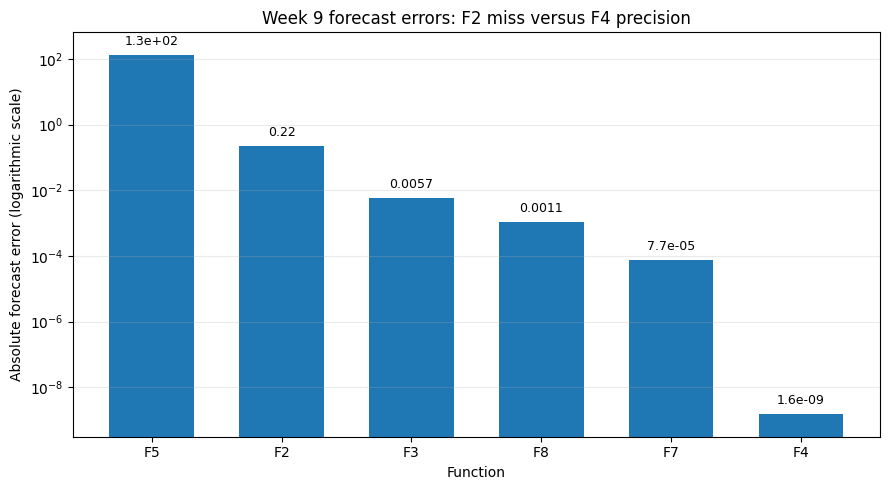

,Function,Pre_result_forecast,Actual,Absolute_error
1,2,0.730502,0.505526,2.249768e-01
2,3,-0.020112,-0.025816,5.704484e-03
3,4,0.658933,0.658933,1.561322e-09
4,5,6454.000000,6583.561445,1.295614e+02
6,7,1.786415,1.786338,7.693295e-05
7,8,9.933511,9.932443,1.068299e-03


These are historical recorded forecasts, not scores for unqueried model proposals.
Different functions have different output scales; this is not a fair cross-function performance ranking.


In [8]:
audit = pd.read_csv(ROOT / 'results/week9_forecast_audit.csv')
paired = audit.dropna(subset=['Pre_result_forecast', 'Actual', 'Absolute_error']).copy()
assert len(paired) >= 4
assert (paired['Absolute_error'] > 0).all()

# Raw scores have radically different scales: F5 is measured in thousands,
# while F4's forecast error is about one billionth. A logarithmic error axis
# makes the relative order-of-magnitude differences visible without
# pretending that the objectives themselves share a common scale.
paired = paired.sort_values('Absolute_error', ascending=False)
labels = [f"F{int(f)}" for f in paired['Function']]
errors = paired['Absolute_error'].to_numpy(float)

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(labels, errors, width=0.65)
ax.set_yscale('log')
ax.set_ylim(errors.min() / 5, errors.max() * 5)
for bar, value in zip(bars, errors):
    ax.annotate(f"{value:.2g}", (bar.get_x() + bar.get_width()/2, value),
                xytext=(0, 5), textcoords='offset points',
                ha='center', va='bottom', fontsize=9)
ax.set(xlabel='Function', ylabel='Absolute forecast error (logarithmic scale)',
       title='Week 9 forecast errors: F2 miss versus F4 precision')
ax.grid(axis='y', which='both', alpha=0.25)
plt.tight_layout()
plt.show()

display(paired[['Function', 'Pre_result_forecast', 'Actual', 'Absolute_error']].sort_values('Function'))
print('These are historical recorded forecasts, not scores for unqueried model proposals.')
print('Different functions have different output scales; this is not a fair cross-function performance ranking.')

## Part C · Mathematical reconstruction and validation

Here, **a reconstructed formula is not the undisclosed source code**. Validation against held-out observed scores demonstrates predictive agreement, not global identity. Every new model evaluation is labelled as a prediction.

### C1. F1: fit the separately supplied Gabor-type model family

A separate working script supplied a two-component Gaussian–cosine *functional family*. With this family and an informed starting point, the reproducible Python fit estimates six parameters from **10 course-provided initial F1 observations only**, then checks the **13 later portal evaluations** without fitting to them. No peer observations enter this test. It is **not** evidence that the family was blindly discovered from ten points or that the fit was used to select Round 11.

In [9]:
x1, y1, initial1 = load_own_observations(ROOT)
fitted_f1 = fit_initial_only(x1[initial1], y1[initial1])
f1_check = validate_held_out(x1[~initial1], y1[~initial1], fitted_f1)
display(pd.DataFrame({'Parameter': list(vars(fitted_f1)), 'Fitted value': list(vars(fitted_f1).values())}))
display(pd.DataFrame([f1_check]))
f1_r11 = predict_f1(np.array([[0.628540, 0.628540]]), fitted_f1)[0]
print('F1 model at recorded R11 query:', format(f1_r11, '.16f'))
print('Actual R11 portal return:       1.9999999996761817')
print('All 13 held-out portal observations pass the signed, nonzero-relative-error checks.')


,Parameter,Fitted value
0,minor_amplitude,1.00000
1,major_amplitude,2.00000
2,minor_centre,0.42146
3,major_centre,0.62854
4,decay,1600.00000
5,frequency,40.00000


,count,zero_count,max_relative_error_nonzero,max_absolute_error
0,13,1,3.029799e-13,4.685141e-14


F1 model at recorded R11 query: 1.9999999996761348
Actual R11 portal return:       1.9999999996761817
All 13 held-out portal observations pass the signed, nonzero-relative-error checks.


The two model-only charts below show the reconstructed narrow peaks. They remain distinct from the observed-only historical plots: [2D reconstruction](../results/figures/f1_model_2d.svg) · [3D reconstruction](../results/figures/f1_model_3d.svg), now with a rotated view. Source and reproducibility: [F1 reconstruction](../src/bbo/f1_reconstruction.py).

### C2. F8: test a simple structural model against later evidence

F8's model is an **additive quadratic with 17 coefficients**. The fitting routine uses the **40 course-provided points only**, then predicts the next **13 personal portal outputs** without fitting to them.

This test was conducted retrospectively after the capstone. It demonstrates that a simple equation already fitted the initial evidence exceptionally well; it does not claim I had identified it in Round 1.

In [10]:
f8 = recover_f8(ROOT)
assert f8['rank'] == 17
assert f8['initial_count'] == 40 and f8['holdout_count'] == 13
assert f8['max_holdout_error'] < 2e-14
assert abs(f8['maximum'] - 10) < 1e-12

print('Full-rank coefficients:', f8['rank'])
print('Fitted optimum coordinates:', np.round(f8['centre'], 6))
print('Fitted optimum score:', round(f8['maximum'], 12))
print('Maximum absolute prediction error on 13 later returns:',
      f"{f8['max_holdout_error']:.3e}")
print('Curvature ratio, x3 to x8:', f8['weights'][2] / f8['weights'][7])

Full-rank coefficients: 17
Fitted optimum coordinates: [0.1  0.15 0.13 0.15 0.8  0.5  0.2  0.6 ]
Fitted optimum score: 10.0
Maximum absolute prediction error on 13 later returns: 1.599e-14
Curvature ratio, x3 to x8: 30.000000000006345


### Visualise the F8 equation

Because F8 has **eight inputs**, this plot shows a **two-input slice**, not the entire function. Only x3 and x8 vary; all six remaining values stay at the fitted optimum. This makes their different curvature weights visible.

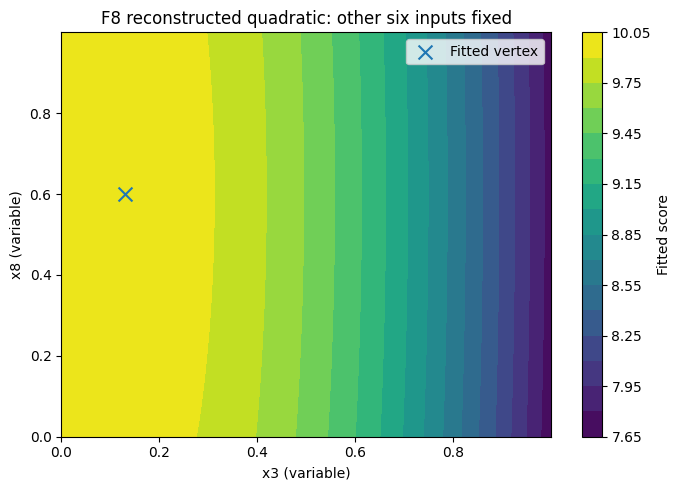

In [11]:
xs = np.linspace(0, .999999, 100)
x3, x8 = np.meshgrid(xs, xs)
# The additive model is f(x) = peak - sum(weight_j * (x_j - centre_j)**2).
# Fixing the other six coordinates at centre makes their squared terms zero.
surface = (f8['maximum']
           - f8['weights'][2] * (x3 - f8['centre'][2])**2
           - f8['weights'][7] * (x8 - f8['centre'][7])**2)

fig, ax = plt.subplots(figsize=(7, 5))
contours = ax.contourf(x3, x8, surface, levels=22)
ax.scatter([f8['centre'][2]], [f8['centre'][7]], marker='x', s=100, label='Fitted vertex')
ax.set(xlabel='x3 (variable)', ylabel='x8 (variable)',
       title='F8 reconstructed quadratic: other six inputs fixed')
ax.legend()
fig.colorbar(contours, ax=ax, label='Fitted score')
plt.tight_layout()
plt.show()

### F8 input sensitivity: eight one-variable curves

The two-dimensional contour above shows only x3 and x8. To make the whole eight-input additive formula easier to interpret, these eight plots vary **one input at a time**, while the other seven stay fixed at the fitted optimum. The plots share the **same vertical scale**, so the differing curvature is directly comparable between inputs.

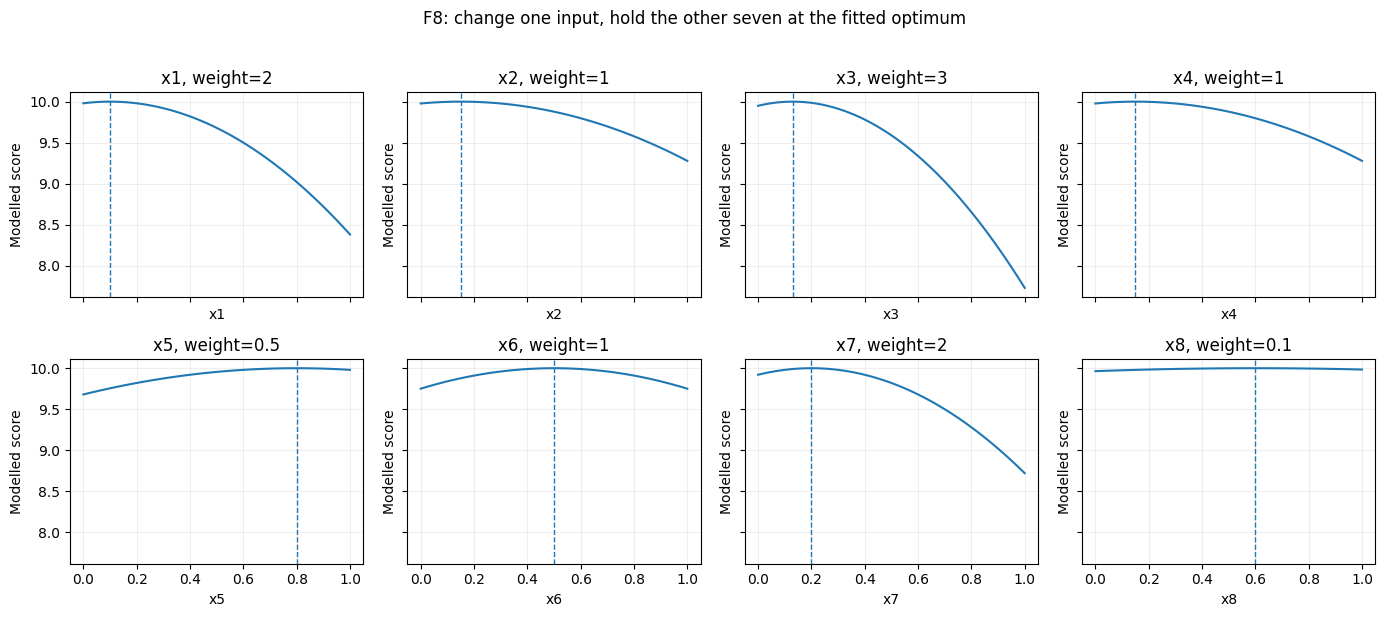

In [12]:
fig, axs = plt.subplots(2, 4, figsize=(14, 6), sharex=True, sharey=True)
grid = np.linspace(0, .999999, 121)
for j, ax in enumerate(axs.flat):
    values = f8['maximum'] - f8['weights'][j] * (grid - f8['centre'][j])**2
    ax.plot(grid, values)
    ax.axvline(f8['centre'][j], linestyle='--', linewidth=1)
    ax.set(title=f"x{j+1}, weight={f8['weights'][j]:g}", xlabel=f"x{j+1}", ylabel='Modelled score')
    ax.grid(alpha=.2)
plt.suptitle('F8: change one input, hold the other seven at the fitted optimum', y=1.02)
plt.tight_layout()
plt.show()

### C3. F7: positive Hartmann-6 and verified Round 11 evidence

The positive Hartmann-6 hypothesis has a documented *pre-result* prediction for Round 12. The independent Python implementation below evaluates the recorded coefficients against **all 43 known F7 outputs**. Because those observations also informed the overall research journey, this full-history check is a **retrospective consistency test**, not an unbiased 43-point holdout.

**Round 11 is fully known:** input `0.233000-0.128000-0.522000-0.276000-0.310000-0.667000`, result `3.278967926227992`, confirmed from the official email. Only the original candidate-generating script remains unavailable.

In [13]:
f7_validation = validate_recorded_f7(ROOT)
display(pd.DataFrame([f7_validation]).T.rename(columns={0: 'Verified value'}))
f7_rows = observations.loc[observations['function'] == 7].copy()
f7_r11 = f7_rows.loc[f7_rows['round'] == 11].iloc[0]
f7_r12 = f7_rows.loc[f7_rows['round'] == 12].iloc[0]
assert np.allclose(
    f7_r11[['x1','x2','x3','x4','x5','x6']].to_numpy(dtype=float),
    [0.233,0.128,0.522,0.276,0.310,0.667],rtol=0,atol=1e-12
)
assert abs(float(f7_r11['output'])-3.278967926227992)<1e-14
print('Confirmed R11 F7 score:', float(f7_r11['output']))
print('Confirmed R12 F7 score:', float(f7_r12['output']))
print('Reconstructed model R12 score:', f7_validation['round12_predicted'])


,Verified value
records,4.300000e+01
max_absolute_error,4.440892e-16
round11_predicted,3.278968e+00
round12_predicted,3.322368e+00
round12_actual,3.322368e+00


Confirmed R11 F7 score: 3.278967926227992
Confirmed R12 F7 score: 3.322368011393156
Reconstructed model R12 score: 3.3223680113931557


The following plot is a **two-input slice of the reconstructed model**. Inputs x3–x6 are held at the Round 12 submitted values. It is not an additional oracle experiment or a complete visualisation of six dimensions.

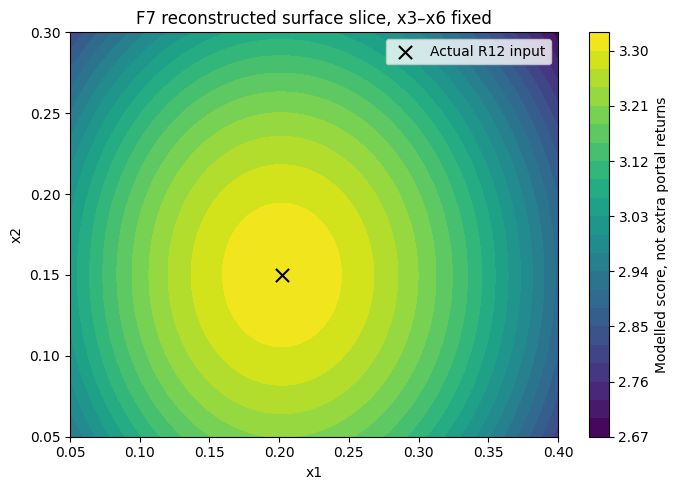

In [14]:
u = np.linspace(0.05, 0.40, 75)
v = np.linspace(0.05, 0.30, 75)
x1_slice, x2_slice = np.meshgrid(u, v)
fixed = [float(f7_r12[f'x{i}']) for i in range(3, 7)]
model_inputs = np.column_stack([
    x1_slice.ravel(), x2_slice.ravel(),
    *[np.full(x1_slice.size, value) for value in fixed]
])
f7_slice = f7_hypothesis(model_inputs).reshape(x1_slice.shape)
fig, ax = plt.subplots(figsize=(7, 5))
mesh = ax.contourf(x1_slice, x2_slice, f7_slice, levels=24)
ax.scatter([float(f7_r12['x1'])], [float(f7_r12['x2'])],
           marker='x', color='black', s=90, label='Actual R12 input')
ax.set(xlabel='x1', ylabel='x2', title='F7 reconstructed surface slice, x3–x6 fixed')
ax.legend()
fig.colorbar(mesh, ax=ax, label='Modelled score, not extra portal returns')
plt.tight_layout()
plt.show()


### C4. F5: check the recorded boundary

The reconstructed F5 power-sum equation was identified **after** my successful Round 10 boundary query. The portal's legal maximum coordinate was **0.999999**, not 1.000000. This check ensures the comparison uses the actual permitted setting, avoiding a misleading mathematical corner value.

In [15]:
legal_corner = np.full(4, 0.999999)
f5_model = f5_at(legal_corner)
f5_portal = 8662.405001248297
assert abs(f5_model - f5_portal) < 1e-9
print('Permitted input:', [float(x) for x in legal_corner])
print('Reconstructed value:', f"{f5_model:.12f}")
print('Confirmed portal value:', f"{f5_portal:.12f}")

Permitted input: [0.999999, 0.999999, 0.999999, 0.999999]
Reconstructed value: 8662.405001248297
Confirmed portal value: 8662.405001248297


## D. Scope, reproducibility and limitations

**What runs:** all **104 real personal queries** are cross-checked with their source ledgers; a fitted GP/EI example and smaller HEBO-inspired/TuRBO-style challengers generate *unsubmitted proposals*; F1 and F8 coefficients are fitted using starting observations only and validated against later returns; F7's reconstructed Hartmann-6 equation is checked against 43 recorded scores; F5's retrospectively reconstructed boundary value is evaluated.

**What is not reconstructed:** the exact historical optimiser state, random seeds, handwritten decisions and full candidate-selection scripts for every round. F2/F3/F4/F6 do not have verified complete mathematical formulas. **The Round 11 F7 submitted input and output ARE confirmed**, `0.233000-0.128000-0.522000-0.276000-0.310000-0.667000` and `3.278967926227992`. Only the specific historical *selection script* is missing. See [verified facts](../docs/VERIFIED_FACTS.md).

**Provenance and timing:** F1's model family came from separate working code and was not blindly discovered from its initial ten observations. F7's Round 12 prediction has contemporary support, while fitting/evaluating all 43 F7 rows is retrospective. The F8 40-initial/13-later experiment is retrospective. F5's equation was reconstructed after its R10 submission. Official HEBO and BoTorch TuRBO-1 comparisons were added afterwards and use a simulator, not paid portal returns.

**Run locally:** install [notebook requirements](../requirements-notebook.txt), open this notebook in the repository and select **Run All**. GitHub Actions executes the notebook on a clean machine and saves the executed version as an artifact.

[Historical journey](../journey/README.md) · [Methods](../docs/methods.md) · [Datasheet](../DATASHEET.md) · [Model card](../MODEL_CARD.md) · [Evidence rules](../docs/EVIDENCE_RULES.md).